In [20]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style("whitegrid")

# Display all columns
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [21]:
import os

print(os.getcwd())

C:\Users\Yash\EDA


In [22]:
print(os.listdir())

['.ipynb_checkpoints', 'EDA.ipynb', 'retail_sales_dataset.csv']


In [23]:
import os
print(os.getcwd())

C:\Users\Yash\EDA


In [24]:

import os

print(os.getcwd())
print(os.listdir())


C:\Users\Yash\EDA
['.ipynb_checkpoints', 'EDA.ipynb', 'retail_sales_dataset.csv']


In [25]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'EDA.ipynb', 'retail_sales_dataset.csv']


In [26]:
import pandas as pd

df = pd.read_csv("retail_sales_dataset.csv")

df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [27]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 1000
Number of Columns: 9


In [28]:
print(df.columns.tolist())

['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [30]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [31]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [32]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [33]:
df.rename(columns={
    'Transaction ID': 'Transaction_ID',
    'Customer ID': 'Customer_ID',
    'Product Category': 'Category',
    'Price per Unit': 'Price',
    'Total Amount': 'Sales'
}, inplace=True)

print(df.columns.tolist())

['Transaction_ID', 'Date', 'Customer_ID', 'Gender', 'Age', 'Category', 'Quantity', 'Price', 'Sales']


In [34]:
df['Date'] = pd.to_datetime(df['Date'])

print(df['Date'].dtype)

datetime64[us]


In [35]:
print(df.isnull().sum())

Transaction_ID    0
Date              0
Customer_ID       0
Gender            0
Age               0
Category          0
Quantity          0
Price             0
Sales             0
dtype: int64


In [36]:
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include='object').columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum())

Transaction_ID    0
Date              0
Customer_ID       0
Gender            0
Age               0
Category          0
Quantity          0
Price             0
Sales             0
dtype: int64


In [37]:
print("Duplicates before cleaning:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

print("Duplicates after cleaning:", df.duplicated().sum())

Duplicates before cleaning: 0
Duplicates after cleaning: 0


In [38]:
df.select_dtypes(include=np.number).mean()

Transaction_ID    500.500
Age                41.392
Quantity            2.514
Price             179.890
Sales             456.000
dtype: float64

In [39]:
df.select_dtypes(include=np.number).median()

Transaction_ID    500.5
Age                42.0
Quantity            3.0
Price              50.0
Sales             135.0
dtype: float64

In [40]:
df.select_dtypes(include=np.number).mode().iloc[0]

Transaction_ID     1.0
Age               43.0
Quantity           4.0
Price             50.0
Sales             50.0
Name: 0, dtype: float64

In [41]:
df.select_dtypes(include=np.number).std()

Transaction_ID    288.819436
Age                13.681430
Quantity            1.132734
Price             189.681356
Sales             559.997632
dtype: float64

In [42]:
numerical_df = df.select_dtypes(include=np.number)

statistics = pd.DataFrame({
    'Mean': numerical_df.mean(),
    'Median': numerical_df.median(),
    'Mode': numerical_df.mode().iloc[0],
    'Standard Deviation': numerical_df.std()
})

statistics

,Mean,Median,Mode,Standard Deviation
Transaction_ID,500.500,500.5,1.0,288.819436
Age,41.392,42.0,43.0,13.681430
Quantity,2.514,3.0,4.0,1.132734
Price,179.890,50.0,50.0,189.681356
Sales,456.000,135.0,50.0,559.997632


In [43]:
df['Year'] = df['Date'].dt.year

df['Month'] = df['Date'].dt.month

df['Month_Name'] = df['Date'].dt.month_name()

df.head()

,Transaction_ID,Date,Customer_ID,Gender,Age,Category,Quantity,Price,Sales,Year,Month,Month_Name
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,2023,11,November
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,2023,2,February
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,2023,1,January
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,2023,5,May
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,2023,5,May


In [44]:
monthly_sales = df.groupby(
    df['Date'].dt.to_period('M')
)['Sales'].sum()

print(monthly_sales)

Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Sales, dtype: int64


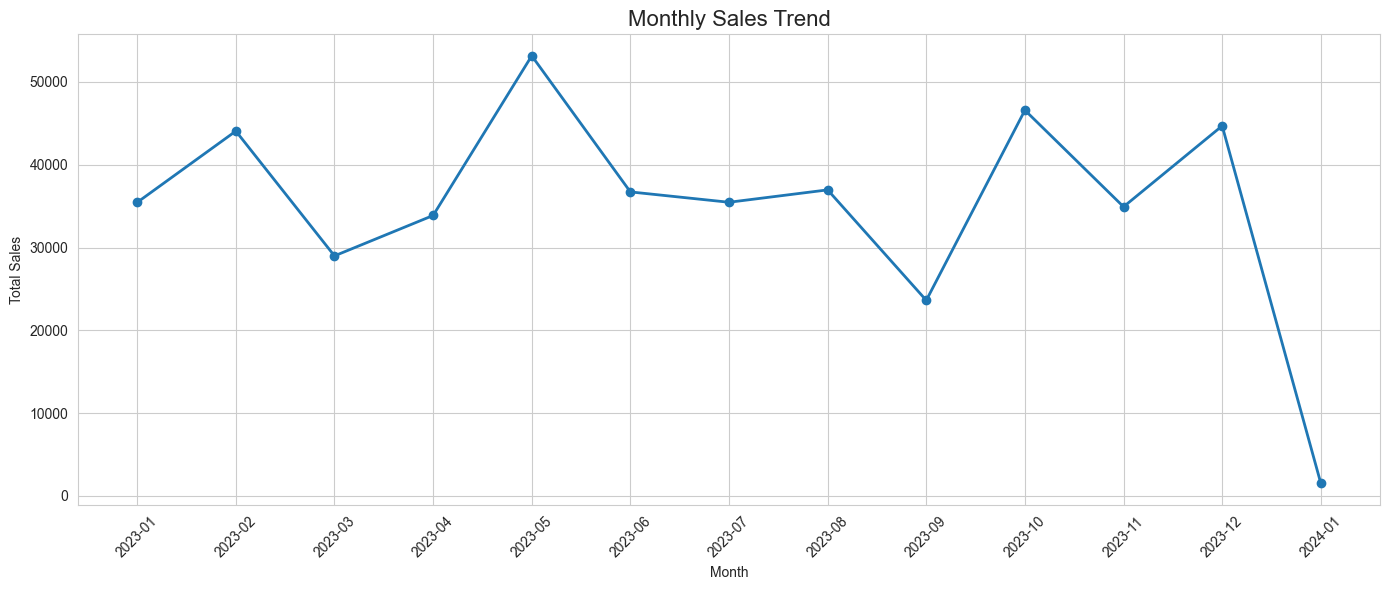

In [45]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker='o',
    linewidth=2
)

plt.title('Monthly Sales Trend', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [46]:
print("Highest Sales Month:")
print(monthly_sales.idxmax(), "-", monthly_sales.max())

print("\nLowest Sales Month:")
print(monthly_sales.idxmin(), "-", monthly_sales.min())

Highest Sales Month:
2023-05 - 53150

Lowest Sales Month:
2024-01 - 1530


In [47]:
quarterly_sales = df.groupby(
    df['Date'].dt.to_period('Q')
)['Sales'].sum()

print(quarterly_sales)

Date
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Sales, dtype: int64


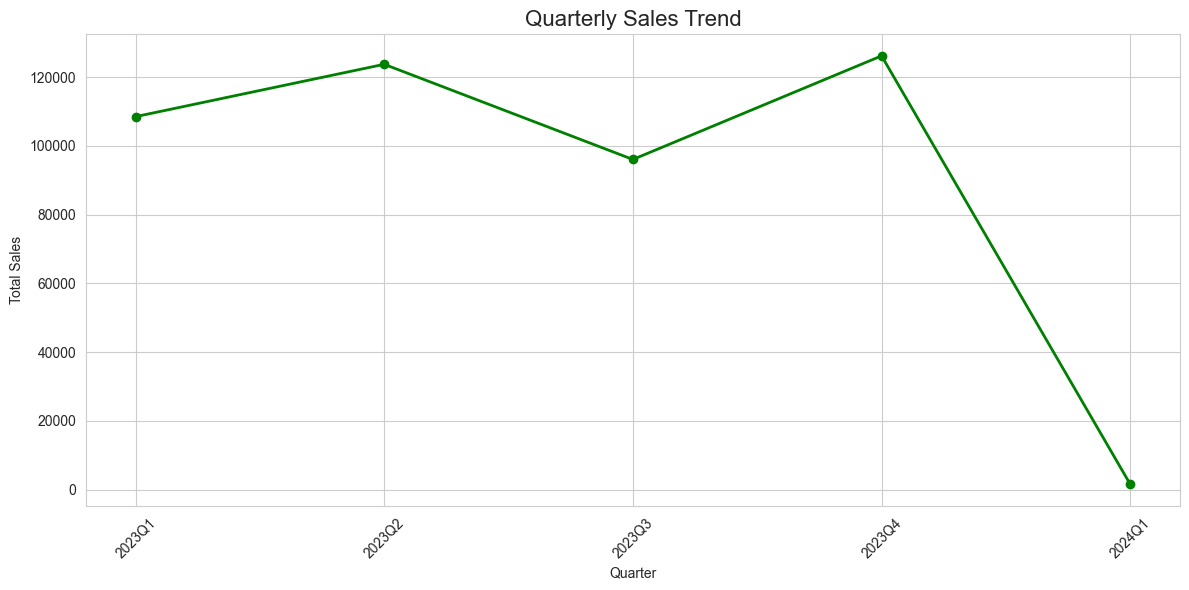

In [48]:
plt.figure(figsize=(12, 6))

plt.plot(
    quarterly_sales.index.astype(str),
    quarterly_sales.values,
    marker='o',
    color='green',
    linewidth=2
)

plt.title('Quarterly Sales Trend', fontsize=16)
plt.xlabel('Quarter')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [49]:
print("Highest Sales Quarter:")
print(quarterly_sales.idxmax(), "-", quarterly_sales.max())

print("\nLowest Sales Quarter:")
print(quarterly_sales.idxmin(), "-", quarterly_sales.min())

Highest Sales Quarter:
2023Q4 - 126190

Lowest Sales Quarter:
2024Q1 - 1530


In [50]:
print("MONTHLY SALES SUMMARY")
display(monthly_sales)

print("\nQUARTERLY SALES SUMMARY")
display(quarterly_sales)

MONTHLY SALES SUMMARY


Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Sales, dtype: int64


QUARTERLY SALES SUMMARY


Date
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Sales, dtype: int64

In [51]:
print("Minimum Age:", df['Age'].min())
print("Maximum Age:", df['Age'].max())
print("Average Age:", df['Age'].mean())
print("Median Age:", df['Age'].median())

Minimum Age: 18
Maximum Age: 64
Average Age: 41.392
Median Age: 42.0


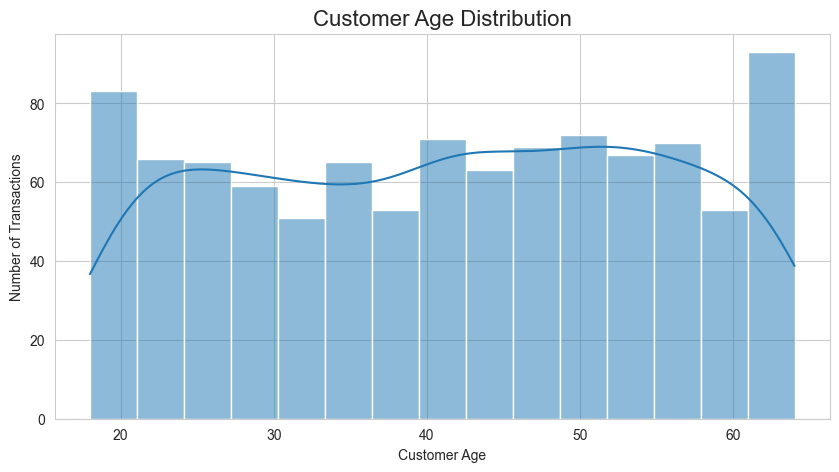

In [52]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='Age',
    bins=15,
    kde=True
)

plt.title('Customer Age Distribution', fontsize=16)
plt.xlabel('Customer Age')
plt.ylabel('Number of Transactions')

plt.show()

In [53]:
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[0, 18, 25, 35, 45, 55, 100],
    labels=[
        'Below 18',
        '18-25',
        '26-35',
        '36-45',
        '46-55',
        'Above 55'
    ],
    right=False
)

df[['Age', 'Age Group']].head(10)

,Age,Age Group
0,34,26-35
1,26,26-35
2,50,46-55
3,37,36-45
4,30,26-35
5,45,46-55
6,46,46-55
7,30,26-35
8,63,Above 55
9,52,46-55


In [54]:
age_distribution = df['Age Group'].value_counts().sort_index()

print(age_distribution)

Age Group
Below 18      0
18-25       149
26-35       203
36-45       207
46-55       225
Above 55    216
Name: count, dtype: int64


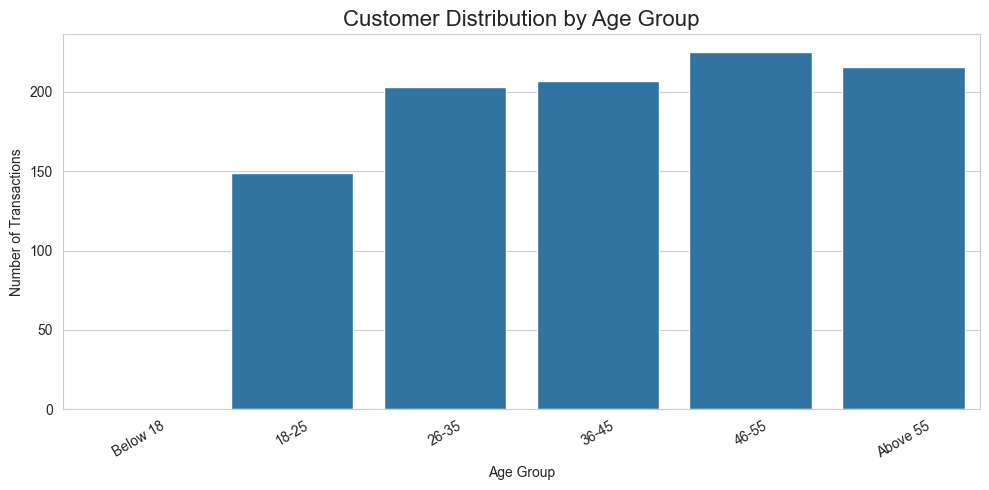

In [55]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='Age Group',
    order=df['Age Group'].cat.categories
)

plt.title('Customer Distribution by Age Group', fontsize=16)
plt.xlabel('Age Group')
plt.ylabel('Number of Transactions')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [56]:
print("Largest Customer Age Group:")
print(age_distribution.idxmax())

print("\nNumber of Transactions:")
print(age_distribution.max())

Largest Customer Age Group:
46-55

Number of Transactions:
225


In [57]:
gender_count = df['Gender'].value_counts()

print(gender_count)

Gender
Female    510
Male      490
Name: count, dtype: int64


In [58]:
gender_percentage = df['Gender'].value_counts(normalize=True) * 100

print(gender_percentage.round(2))

Gender
Female    51.0
Male      49.0
Name: proportion, dtype: float64


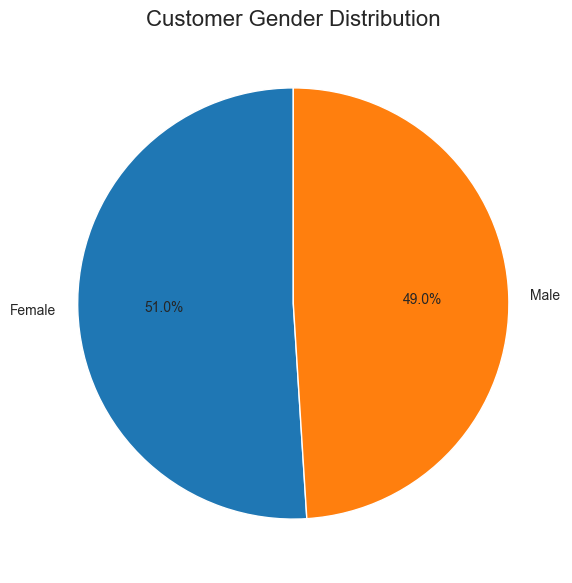

In [59]:
plt.figure(figsize=(7, 7))

plt.pie(
    gender_count,
    labels=gender_count.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Gender Distribution', fontsize=16)

plt.show()

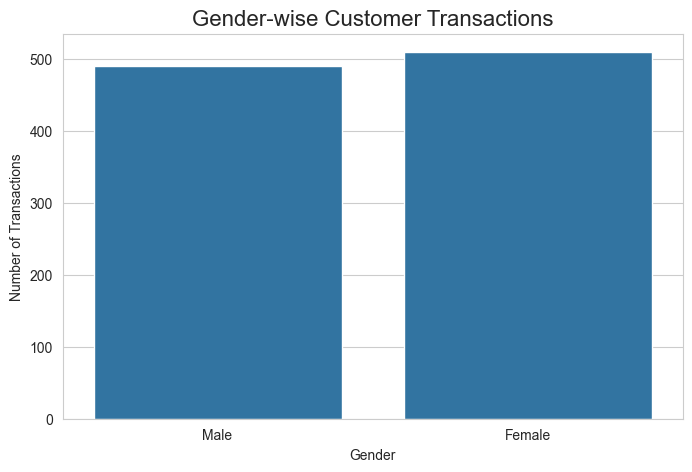

In [60]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Gender'
)

plt.title('Gender-wise Customer Transactions', fontsize=16)
plt.xlabel('Gender')
plt.ylabel('Number of Transactions')

plt.show()

In [61]:
gender_sales = df.groupby('Gender')['Sales'].sum()

print(gender_sales)

Gender
Female    232840
Male      223160
Name: Sales, dtype: int64


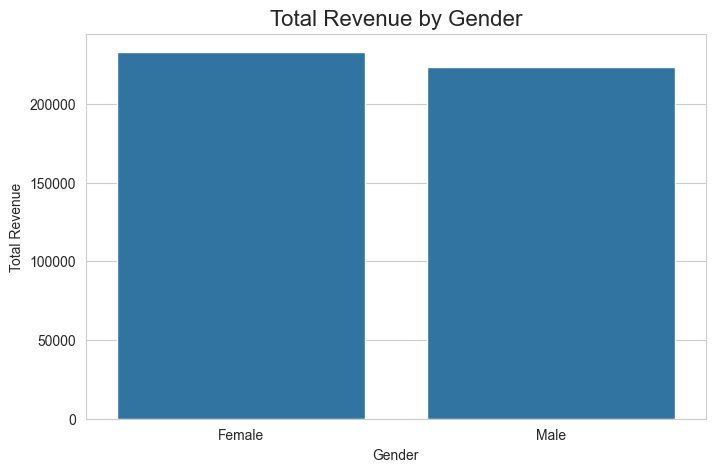

In [62]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=gender_sales.index,
    y=gender_sales.values
)

plt.title('Total Revenue by Gender', fontsize=16)
plt.xlabel('Gender')
plt.ylabel('Total Revenue')

plt.show()

In [63]:
print("========== CUSTOMER DEMOGRAPHICS ==========")

print("\nAverage Customer Age:")
print(round(df['Age'].mean(), 2))

print("\nLargest Age Group:")
print(age_distribution.idxmax())

print("\nGender Distribution:")
print(gender_count)

print("\nRevenue by Gender:")
print(gender_sales)

========== CUSTOMER DEMOGRAPHICS ==========

Average Customer Age:
41.39

Largest Age Group:
46-55

Gender Distribution:
Gender
Female    510
Male      490
Name: count, dtype: int64

Revenue by Gender:
Gender
Female    232840
Male      223160
Name: Sales, dtype: int64


In [64]:
print(df.columns.tolist())

['Transaction_ID', 'Date', 'Customer_ID', 'Gender', 'Age', 'Category', 'Quantity', 'Price', 'Sales', 'Year', 'Month', 'Month_Name', 'Age Group']


In [65]:
print("Product Categories:")
print(df['Category'].unique())

Product Categories:
<StringArray>
['Beauty', 'Clothing', 'Electronics']
Length: 3, dtype: str


In [66]:
top_products = df.groupby('Category')['Quantity'].sum().sort_values(
    ascending=False
).head(10)

print(top_products)

Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


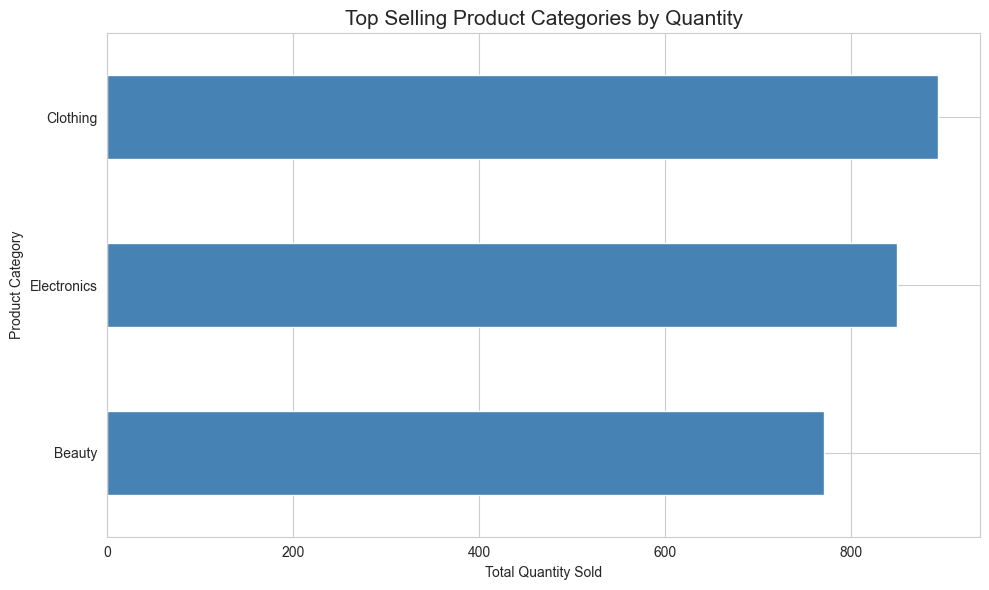

In [67]:
plt.figure(figsize=(10, 6))

top_products.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('Top Selling Product Categories by Quantity', fontsize=15)
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

In [68]:
category_sales = df.groupby('Category')['Sales'].sum().sort_values(
    ascending=False
)

print(category_sales)

Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Sales, dtype: int64


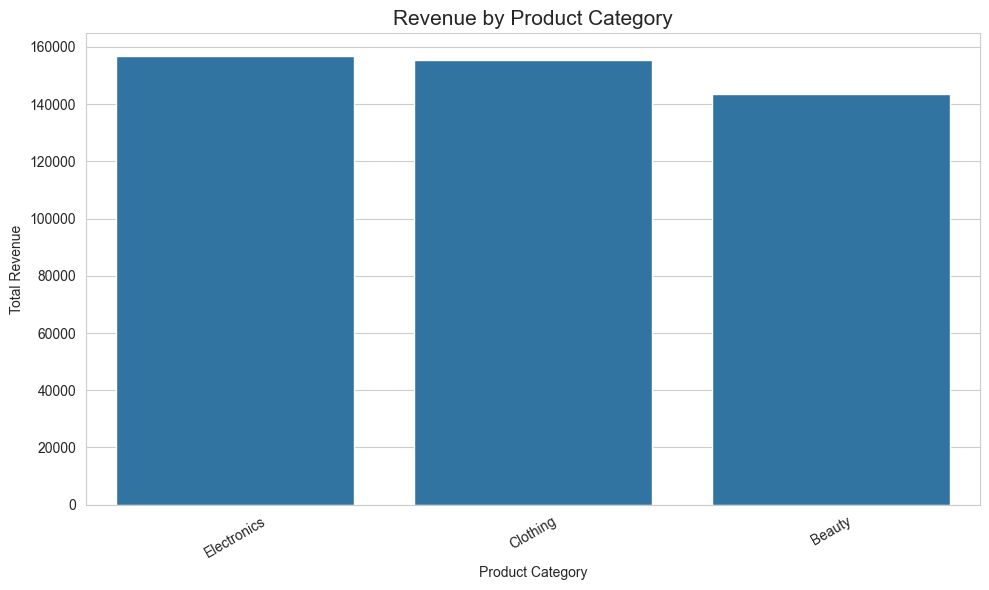

In [69]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title('Revenue by Product Category', fontsize=15)
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [70]:
print("Highest Revenue Category:")
print(category_sales.idxmax())

print("\nHighest Revenue:")
print(category_sales.max())

Highest Revenue Category:
Electronics

Highest Revenue:
156905


In [71]:
category_percentage = (
    category_sales / category_sales.sum()
) * 100

print(category_percentage.round(2))

Category
Electronics    34.41
Clothing       34.12
Beauty         31.47
Name: Sales, dtype: float64


In [72]:
numerical_data = df.select_dtypes(include=np.number)

# Remove identifier columns
numerical_data = numerical_data.drop(
    columns=['Transaction_ID'],
    errors='ignore'
)

numerical_data.head()

,Age,Quantity,Price,Sales,Year,Month
0,34,3,50,150,2023,11
1,26,2,500,1000,2023,2
2,50,1,30,30,2023,1
3,37,1,500,500,2023,5
4,30,2,50,100,2023,5


In [73]:
correlation = numerical_data.corr()

print(correlation)

               Age  Quantity     Price     Sales      Year     Month
Age       1.000000 -0.023737 -0.038423 -0.060568  0.023269 -0.000640
Quantity -0.023737  1.000000  0.017501  0.373707 -0.020324 -0.021803
Price    -0.038423  0.017501  1.000000  0.851925  0.020097 -0.008161
Sales    -0.060568  0.373707  0.851925  1.000000  0.024714 -0.005197
Year      0.023269 -0.020324  0.020097  0.024714  1.000000 -0.071981
Month    -0.000640 -0.021803 -0.008161 -0.005197 -0.071981  1.000000


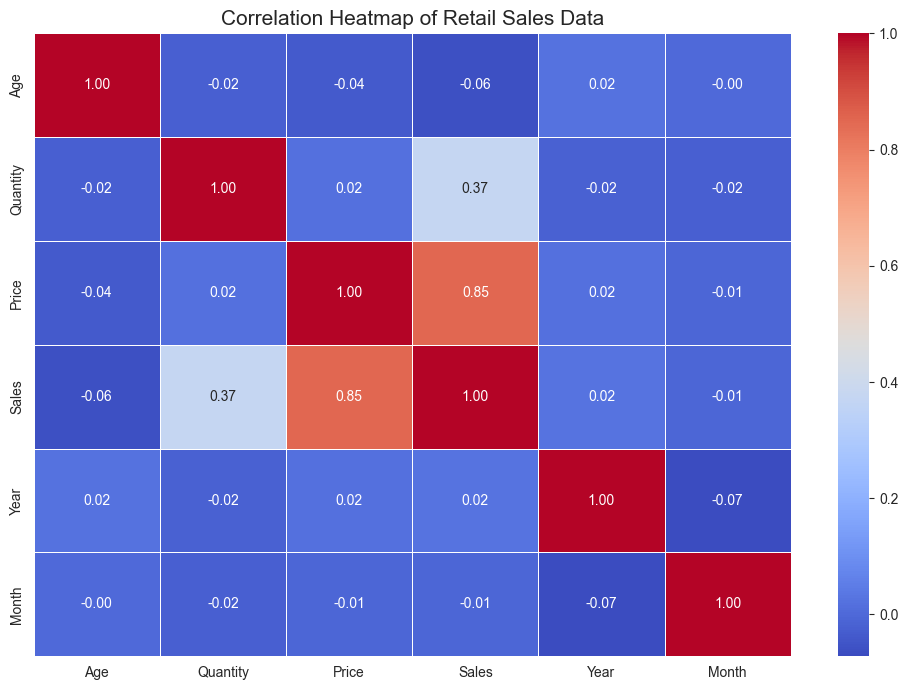

In [74]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Retail Sales Data', fontsize=15)

plt.tight_layout()
plt.show()

In [75]:
df['Day'] = df['Date'].dt.day_name()

day_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

print(df[['Date', 'Day']].head())

        Date       Day
0 2023-11-24    Friday
1 2023-02-27    Monday
2 2023-01-13    Friday
3 2023-05-21    Sunday
4 2023-05-06  Saturday


In [76]:
day_sales = df.groupby('Day')['Sales'].sum().reindex(day_order)

print(day_sales)

Day
Monday       70250
Tuesday      69440
Wednesday    58770
Thursday     53835
Friday       66290
Saturday     78815
Sunday       58600
Name: Sales, dtype: int64


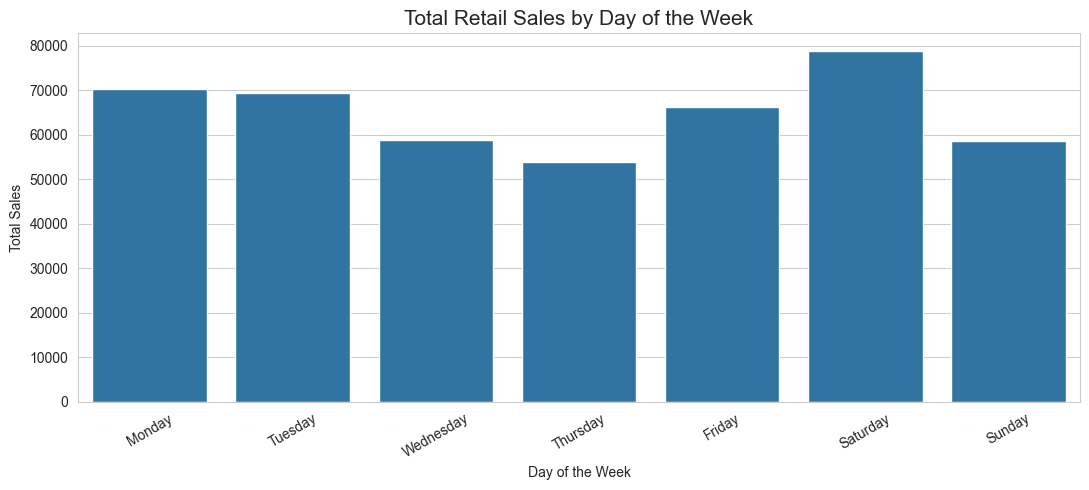

In [77]:
plt.figure(figsize=(11, 5))

sns.barplot(
    x=day_sales.index,
    y=day_sales.values
)

plt.title('Total Retail Sales by Day of the Week', fontsize=15)
plt.xlabel('Day of the Week')
plt.ylabel('Total Sales')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [78]:
print("Highest Sales Day:")
print(day_sales.idxmax(), "-", day_sales.max())

print("\nLowest Sales Day:")
print(day_sales.idxmin(), "-", day_sales.min())

Highest Sales Day:
Saturday - 78815

Lowest Sales Day:
Thursday - 53835


In [79]:
print("========== RETAIL SALES BUSINESS SUMMARY ==========")

print("\nTotal Revenue:")
print(df['Sales'].sum())

print("\nTotal Quantity Sold:")
print(df['Quantity'].sum())

print("\nAverage Transaction Value:")
print(df['Sales'].mean())

print("\nHighest Revenue Category:")
print(category_sales.idxmax())

print("\nBest Sales Day:")
print(day_sales.idxmax())

print("\nLargest Customer Age Group:")
print(age_distribution.idxmax())

print("\nMost Common Gender:")
print(gender_count.idxmax())

========== RETAIL SALES BUSINESS SUMMARY ==========

Total Revenue:
456000

Total Quantity Sold:
2514

Average Transaction Value:
456.0

Highest Revenue Category:
Electronics

Best Sales Day:
Saturday

Largest Customer Age Group:
46-55

Most Common Gender:
Female
